# Processing a data packet: step-by-step walkthrough of `process_packet.py`

`process_packet.py` turns one packet (its manifest plus the raw files) into training data:

| step | input | output |
|---|---|---|
| 1. find the files | manifest | paths to the trace files, image `.meta` and FITS files on this computer |
| 2. traces | `.RJ45ADCDATA<ch>` | `traces/*.npz` (every decoded sample) and `features.json` (quality and tools per trace; per board and channel the mean over the 3 repeated sets, their scatter, and the difference from the reference) |
| 3. images | `avg_img_*.fits.bz2` | `fits/*.fits` (decompressed), `waders/acm<board>/` (panaSKImg output, log, command, JSON) |
| 4. labels | WADERs output header | `labels.json`: gain, σe, λ with errors and fit-quality flags, per board and channel |
| 5. grouping | every `result.json` | `dataset.csv` / `dataset.jsonl`: one row per (packet, board, channel) |

**The packet used here is the rehearsal packet from `take_packet_walkthrough.ipynb`.** It has
2 boards × 4 channels × (3 reference + 3 θ) trace sets = 48 traces, and 2 images. Its files are
copies of older real data:

* board 101's traces are the five 2026-10-08 repeats, cycled;
* board 102's traces are the single 2026-10-06 trace of each channel, copied every time;
* each board's image is the 2026-10-06 100×1000×3000 image.

They are **not** measurements at the packet's settings. Everything below is real processing, but
the numbers describe those old files.

In [1]:
import json, sys, csv, bz2
from pathlib import Path
from pprint import pprint
import numpy as np
import matplotlib.pyplot as plt

PROJECT = Path.cwd().parent
sys.path.insert(0, str(PROJECT / "src"))
REHEARSAL = PROJECT / "rehearsal"

import process_packet as pp
from decode_trace import decode_trace
from trace_regions import split_regions
from compare_trace import measure, usable_pixels, row_start_pixels

MANIFEST = REHEARSAL / "work" / "packets" / "example_00001.json"
if not MANIFEST.exists():                      # make the rehearsal packet if notebook 1 was not run
    import take_packet as tp
    from ccd_limits import Limits
    setup = tp.DaqSetup.load(PROJECT / "configs" / "daq_setup.toml")
    setup.work_dir = str(REHEARSAL / "work")
    request = tp.request_from_params(tp.load_toml_or_json(PROJECT / "configs" / "packet_example.toml"), setup)
    tp.take_packet(tp.make_controller("fake", setup, str(PROJECT / "data")), request, setup,
                   Limits.load(PROJECT / "configs" / "limits.toml"), None, allow_unreviewed_limits=True)

cfg = pp.ProcessingConfig.load(PROJECT / "configs" / "processing.toml")
cfg.out_dir = REHEARSAL / "processed"          # for this walkthrough
OUT = cfg.out_dir / "example_00001"
print("manifest :", MANIFEST.relative_to(PROJECT))
print("output   :", OUT.relative_to(PROJECT))
print("WADERs   :", " ".join(cfg.waders_command), "| JSON:", cfg.waders_json.name)

manifest : rehearsal/work/packets/example_00001.json
output   : rehearsal/processed/example_00001
WADERs   : /opt/homebrew/Caskroom/miniforge/base/bin/conda run -n damic panaSKImg | JSON: img_9.json


## Step 1: the manifest and the files

The manifest stores file **stems** (the name without extension) exactly as acmpy reported them on
the DAQ machine. A trace of channel *c* is `<stem>.RJ45ADCDATA<c>`; the other three files of that
acquisition are empty frames, because only channel *c* was at level 0. An image has a `.meta`, four
`.RJ45ADCDATA` files, and the image builder's `avg_<stem>.fits.bz2`.

When processing on another computer, the DAQ paths (`/home/damicm/run/...`) are replaced by the
local copy through `[paths]` in `configs/processing.toml`:

In [2]:
print("path map:", cfg.path_map)
daq_path = "/home/damicm/run/PA_PQ_testing/2026-10-06-PA03_PQ04_Installation_Check130K_1/img_x"
print(daq_path, "\n  ->", pp.localize(daq_path, cfg.path_map))

path map: {'/home/damicm/run/PA_PQ_testing': '/Users/dylanrosenmerkel/Documents/Software/ccd_opt_ml/data'}
/home/damicm/run/PA_PQ_testing/2026-10-06-PA03_PQ04_Installation_Check130K_1/img_x 
  -> /Users/dylanrosenmerkel/Documents/Software/ccd_opt_ml/data/2026-10-06-PA03_PQ04_Installation_Check130K_1/img_x


In [3]:
manifest = json.loads(MANIFEST.read_text())
print("packet", manifest["packet_id"], "| status", manifest["status"], "| Δθ per board", manifest["delta_theta"])
files = pp.packet_files(manifest, cfg)
print(f"\n{len(files['traces'])} traces, all present: {all(t['data'].exists() for t in files['traces'])}")
print(f"{'kind':6s} {'board':5s} {'ch':3s} {'set':3s} data file")
for t in files["traces"][:5]:
    print(f"{t['kind']:6s} {t['board']:<5d} {t['channel']:<3d} {t['repeat']:<3d} {t['data'].name}")
print("...")
for im in files["images"]:
    print(f"image acm{im['board']}: {im['fits'].name}  exists={im['fits'].exists()}")

packet example_00001 | status ok | Δθ per board {'101': {'VSUB': 3.0}, '102': {'VSUB': 5.0}}

48 traces, all present: True
kind   board ch  set data file
ref    101   0   1   example_00001_ref_traces1_2x5x500_20x20_ch0_101_20261009_152328_0.RJ45ADCDATA0
ref    101   1   1   example_00001_ref_traces1_2x5x500_20x20_ch1_101_20261009_152328_1.RJ45ADCDATA1
ref    101   2   1   example_00001_ref_traces1_2x5x500_20x20_ch2_101_20261009_152328_2.RJ45ADCDATA2
ref    101   3   1   example_00001_ref_traces1_2x5x500_20x20_ch3_101_20261009_152328_3.RJ45ADCDATA3
ref    102   0   1   example_00001_ref_traces1_2x5x500_20x20_ch0_102_20261009_152328_0.RJ45ADCDATA0
...
image acm101: avg_example_00001_img_100x130x500_1x10_L2_101_20261009_152332_28.fits.bz2  exists=True
image acm102: avg_example_00001_img_100x130x500_1x10_L2_102_20261009_152332_24.fits.bz2  exists=True


## Step 2: traces

### 2a. Decode and check one trace

`decode_trace.py` reads the big-endian 32-bit words. It separates the raw ADC samples (20-bit
signed values plus 12 flag bits: RD = pedestal window, RU = signal window, ...) from the inline L1
records (the firmware's sum of each 150-sample window). `check_l1()` recomputes every window sum
from the raw samples: 0 means the raw samples, the flags and the firmware sums agree exactly.
`quality_problems()` is the check that found the damaged 2026-10-08 trace.

raw samples      : 3024671 (201.6 ms at 15 MHz)
inline L1 records: 10010 | pixels [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
inline vs raw    : 0 (0 = exact agreement)
quality problems : none


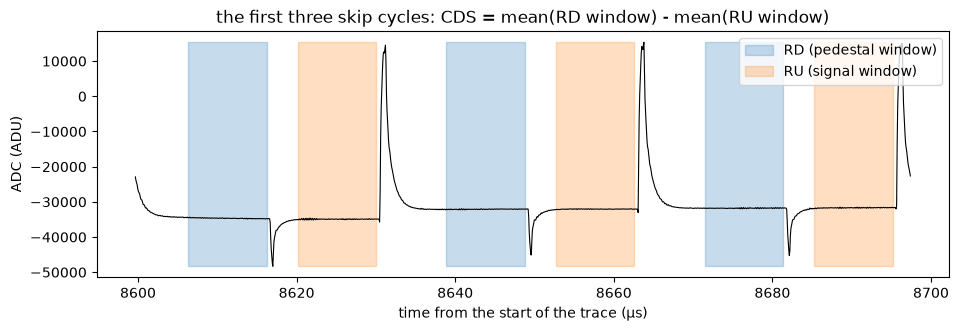

In [4]:
entry = next(t for t in files["traces"] if t["kind"] == "theta" and t["board"] == 101 and t["channel"] == 0)
trace = decode_trace(entry["data"])
print("raw samples      :", len(trace.values), f"({len(trace.values) / 15e6 * 1e3:.1f} ms at 15 MHz)")
print("inline L1 records:", len(trace.l1_sum), "| pixels", np.unique(trace.l1_pixel).tolist())
print("inline vs raw    :", trace.check_l1(), "(0 = exact agreement)")
print("quality problems :", trace.quality_problems() or "none")

# The trace starts with vertical and horizontal transfers; plot the first 3 skip cycles of pixel 0.
first_window = trace.window_slices()[0][0]
i0, i1 = first_window - 100, first_window - 100 + 3 * 489
t_us = np.arange(i0, i1) / 15
y = trace.values[i0:i1]
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(t_us, y, lw=0.8, color="k")
ax.fill_between(t_us, y.min(), y.max(), where=trace.rd[i0:i1], color="tab:blue", alpha=0.25, label="RD (pedestal window)")
ax.fill_between(t_us, y.min(), y.max(), where=trace.ru[i0:i1], color="tab:orange", alpha=0.25, label="RU (signal window)")
ax.set(xlabel="time from the start of the trace (µs)", ylabel="ADC (ADU)",
       title="the first three skip cycles: CDS = mean(RD window) - mean(RU window)")
ax.legend(loc="upper right"); plt.show()

### 2b. Regions and usable pixels

`split_regions` cuts the trace into skip cycles, horizontal transfers and vertical transfers, using
the window flags and the gaps between them. Two kinds of pixels are left out of the features
(`pixels = "usable"` in the config):

* the **row-start pixels** (the first pixel of each row), whose baseline is still recovering from the
  vertical transfers;
* pixels holding a large **charge** (CDS mean beyond 8 robust standard deviations), which distorts
  the waveform.

On module 102 the vertical-transfer region is not found: its board uses `Vtransfer21`, and flag
bit 5 does not mark every vertical transfer there. Its 4 vertical tools are then left out. They are
information only anyway.

In [5]:
regions = split_regions(trace)
print("pixels           :", regions.n_pixels)
print("skip cycle       :", regions.period, "samples =", round(regions.period / 15, 1), "µs")
print("row-start pixels :", row_start_pixels(regions))
pixels = usable_pixels(regions)
print("usable pixels    :", pixels)

pixels           : 10
skip cycle       : 489 samples = 32.6 µs
row-start pixels : [0, 5]
usable pixels    : [1, 2, 3, 4, 6, 7, 8, 9]


### 2c. Trace tools

`measure` runs the 39 tools of `compare_trace.py` on every usable pixel (fits, skip tools,
horizontal and vertical transfer tools). For the dataset, each tool becomes **one number per trace**:
the median over the pixels, robust against one odd pixel. The spread over the pixels (1.4826 × MAD)
is kept next to it. Curve tools (e.g. the mean skip shape) keep their median curve and go into the
`.npz` file.

Two fit tools sit at the edge of their search range on these traces (ringing frequency 0.01, correlated
noise floor 0), as already seen in the comparison study. They are kept, but carry little information.

In [6]:
replicates = measure(regions, pixels)
median, spread, curves = pp.summarize_tools(replicates.tools)
print(f"{len(median)} scalar tools, {len(curves)} curves\n")
for name in list(median)[:12]:
    print(f"{name:48s} {median[name]:12.4g}  ± {spread[name]:.3g} (pixel spread)")
print("...")

35 scalar tools, 4 curves

fit: settling time after pulse (us)                    0.6176  ± 0.000789 (pixel spread)
fit: settling amplitude after pulse                 4.311e+04  ± 36.4 (pixel spread)
fit: dip recovery time (us)                            0.3049  ± 0.000858 (pixel spread)
fit: dip recovery amplitude                        -1.209e+04  ± 6.03 (pixel spread)
fit: baseline droop time constant (skips)               235.8  ± 1.41 (pixel spread)
fit: baseline droop amplitude                      -1.794e+04  ± 238 (pixel spread)
fit: first-skip ringing frequency (cyc/skip)             0.01  ± 0 (pixel spread)
fit: first-skip ringing decay (skips)                   1.152  ± 0 (pixel spread)
fit: first-skip ringing amplitude                        6289  ± 73.5 (pixel spread)
fit: white noise per skip (ADU)                         5.524  ± 0.207 (pixel spread)
fit: correlated noise floor (ADU)                           0  ± 0 (pixel spread)
skip: dip height                       

### 2d. The saved format (`.npz`): nothing is thrown away

`process_trace` writes one compressed `.npz` per trace:

* `values` (every ADC sample) and `flags` (all 12 flag bits per sample): **the complete content of
  the raw samples**. RD and RU are bits 0 and 1 of `flags`;
* `l1_pixel`, `l1_is_signal`, `l1_n`, `l1_sum`: the firmware's inline window sums;
* `cds`: pixels × skips matrix of CDS values (pedestal − signal);
* `curve: ...`: the median curves of the curve tools.

The check below reloads the file and compares it with a fresh decode of the raw file.

In [7]:
summary = pp.process_trace(entry, OUT, cfg)
data = np.load(summary["npz"])
print("arrays:", {k: data[k].shape for k in data.files})
print("size  :", round(Path(summary["npz"]).stat().st_size / 1e6, 1), "MB (raw file:",
      round(entry["data"].stat().st_size / 1e6, 1), "MB)")
print("values identical to the raw decode:", np.array_equal(data["values"], trace.values))
print("flags identical                    :", np.array_equal(data["flags"], trace.flags))
print("RD = flag bit 0 identical          :", np.array_equal((data["flags"] & 1) != 0, trace.rd))

arrays: {'values': (3024671,), 'flags': (3024671,), 'l1_pixel': (10010,), 'l1_is_signal': (10010,), 'l1_n': (10010,), 'l1_sum': (10010,), 'cds': (10, 500), 'curve: skip: mean shape': (489,), 'curve: skip: baseline droop curve': (499,), 'curve: horizontal: mean shape': (473,), 'curve: vertical: mean shape': (491,)}
size  : 6.2 MB (raw file: 12.2 MB)
values identical to the raw decode: True
flags identical                    : True
RD = flag bit 0 identical          : True


### 2e. All traces: repeats, scatter, and the change from the reference

The same is done for all 48 traces (about one minute). Then, for every (kind, board, channel),
`combine_repeats` combines the 3 trace sets:

* **mean**: the average of the 3 per-trace values; this goes into the dataset;
* **sd**: their standard deviation, the scatter between sets taken about a minute apart at the same
  settings. This is the **run-to-run noise** of each tool, measured in every packet.

`trace_differences` then gives **mean(θ) − mean(reference)** per board and channel: the amplifier's
change, measured minutes apart on the same amplifier. The training plan uses it to remove each
amplifier's fixed signature.

In this rehearsal, board 101's sets are different real repeats, so their sd is the real 10-08
run-to-run scatter. Board 102's sets are copies of one file, so their sd is exactly 0.

In [8]:
traces = [pp.process_trace(t, OUT, cfg) for t in files["traces"]]
print(sum(t["usable"] for t in traces), "of", len(traces), "traces usable")
combined = pp.combine_repeats(traces)
tools = ["fit: dip recovery time (us)", "skip: pulse peak height", "fit: white noise per skip (ADU)"]
print(f"\n{'kind':6s} {'board':5s} {'ch':3s} " + "  ".join(f"{t[:28]:>30s}" for t in tools))
for c in combined:
    if c["channel"] in (0, 1):
        print(f"{c['kind']:6s} {c['board']:<5d} {c['channel']:<3d} " +
              "  ".join(f"{c['mean'][t]:14.4g} ± {c['sd'][t]:<13.3g}" for t in tools))
diffs = pp.trace_differences(combined)
print("\nmean(θ) − mean(reference), board 101 channel 0:")
d = next(d for d in diffs if d["board"] == 101 and d["channel"] == 0)["difference"]
for t in tools:
    print(f"  {t:36s} {d[t]: .4g}")

48 of 48 traces usable

kind   board ch     fit: dip recovery time (us)         skip: pulse peak height    fit: white noise per skip (A
ref    101   0           0.3029 ± 0.00317             4.645e+04 ± 67.3                    5.641 ± 0.0697       
ref    101   1           0.4612 ± 0.0102               4.43e+04 ± 129                     5.943 ± 0.117        
ref    102   0           0.4606 ± 0                    3.46e+04 ± 0                       4.647 ± 0            
ref    102   1           0.7616 ± 1.36e-16            3.578e+04 ± 0                       4.903 ± 0            
theta  101   0           0.3048 ± 0.000127             4.65e+04 ± 73.2                    5.628 ± 0.0923       
theta  101   1           0.4663 ± 0.00178             4.439e+04 ± 25                      5.971 ± 0.0697       
theta  102   0           0.4606 ± 0                    3.46e+04 ± 0                       4.647 ± 0            
theta  102   1           0.7616 ± 1.36e-16            3.578e+04 ± 0             

For board 101 channel 0 the reference and θ sets come from the same five 10-08 files, so the
differences are pure run-to-run scatter. For example, the pulse peak differs by about the size of
its sd. With real data, a parameter change is visible in a tool only if its difference is well
above that sd.

## Step 3: images

### 3a. Decompress

The image builder writes `avg_<image>.fits.bz2` (the average of the skips of each pixel, all four
channels as extensions 1–4). `decompress_fits` writes the plain `.fits` into the packet's output
folder; the original stays untouched. `read_fits_primary` reads the header without astropy.

Note that the header says 100 × 1000 × 3000 while the file name says 100 × 130 × 500. That is
because the fake board copied an old image. A real packet's header matches its name.

In [9]:
image = files["images"][0]
fits = pp.decompress_fits(image["fits"], OUT / "fits")
with bz2.open(image["fits"], "rb") as f:
    print("decompressed copy is byte-identical:", f.read() == fits.read_bytes())
print("size:", round(image["fits"].stat().st_size / 1e6, 2), "MB ->", round(fits.stat().st_size / 1e6, 2), "MB")
header = pp.read_fits_primary(fits)
print({k: header.get(k) for k in ("ACMID", "NROW", "NCOL", "NDCM", "NPBIN", "NSBIN", "EXPOSURE", "FILTER", "BINNAME")})

decompressed copy is byte-identical: True
size: 1.25 MB -> 1.62 MB
{'ACMID': 101, 'NROW': 100, 'NCOL': 1000, 'NDCM': 3000, 'NPBIN': 1, 'NSBIN': 1, 'EXPOSURE': 10, 'FILTER': 170, 'BINNAME': 'img_100x1000x3000_1x1_L2_101_20261006_132140_1'}


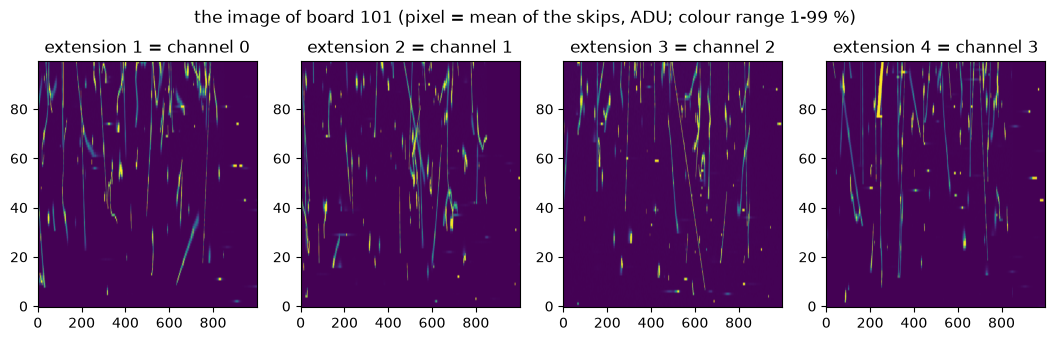

In [10]:
try:
    from astropy.io import fits as afits
    with afits.open(fits) as hdul:
        fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
        for ch, ax in enumerate(axes):
            img = hdul[ch + 1].data
            lo, hi = np.percentile(img, [1, 99])
            ax.imshow(img, origin="lower", aspect="auto", vmin=lo, vmax=hi, cmap="viridis")
            ax.set_title(f"extension {ch + 1} = channel {ch}")
        fig.suptitle("the image of board 101 (pixel = mean of the skips, ADU; colour range 1-99 %)", y=1.04)
        plt.show()
except ImportError:
    print("astropy not installed in this kernel: image display skipped")

### 3b. WADERs (panaSKImg)

The command is assembled from `configs/processing.toml`:

* `--acm`: the FITS file is an ACM multi-extension image, so all four channels are processed together;
* `-j <json>`: the WADERs configuration. `img_9.json` is the file used for the 2026-10-06 image. Its
  process chain is CompressSkipper → PedestalSubtraction (gaussian fit in the overscan) →
  **FitDarkCurrent** → Calibration → ClusterFinder → BuildClusterMask;
* `-o <dir>`: the output folder (must exist; the script creates it).

`run_waders` saves the command line, a copy of the JSON, the complete log, the return code and the
duration. WADERs itself writes the results as header keys of its output FITS file.

In [11]:
run = pp.run_waders(fits, OUT / "waders" / "acm101", cfg)
print("command    :", " ".join(Path(c).name if c.startswith("/") and i > 4 else c for i, c in enumerate(run["command"])))
print("return code:", run["returncode"], "| seconds:", run["seconds"])
print("output     :", Path(run["output"]).name)
print("saved      :", sorted(p.name for p in (OUT / "waders" / "acm101").iterdir()))
print("\nfit results printed in the log:")
for line in Path(run["log"]).read_text().splitlines():
    if "FitDarkCurrentProcess> INFO" in line or line.strip().startswith(("- single-e", "- dark current", "- gain", "- zero-e", "- Noise")):
        print(" ", line.strip())

command    : /opt/homebrew/Caskroom/miniforge/base/bin/conda run -n damic panaSKImg avg_example_00001_img_100x130x500_1x10_L2_101_20261009_152332_28.fits --acm -j img_9.json -o acm101
return code: 0 | seconds: 7.5
output     : avg_example_00001_img_100x130x500_1x10_L2_101_20261009_152332_28_EXT1-EXT2-EXT3-EXT4_waders.fits.bz2
saved      : ['avg_example_00001_img_100x130x500_1x10_L2_101_20261009_152332_28_EXT1-EXT2-EXT3-EXT4_waders.fits.bz2', 'command.txt', 'log.txt', 'panaSKImg_clustersRec_avg_example_00001_img_100x130x500_1x10_L2_101_20261009_152332_28_ext1234.root', 'waders_config_used.json']

fit results printed in the log:
  Process <FitDarkCurrentProcess> INFO. Fit the n-first peaks to estimate the dark current and the calibration constant [amplifier EXT1].
  - zero-e- peak position [ADU] = 0.15969408073035507 +/- 0.0012346490375219066
  - single-e- resolution [ADU] = 0.1422818805180688 +/- 0.0006758488262263024
  - dark current [ADU/bin/img] = 1.3875088136487486 +/- 0.01723355085

## Step 4: labels

WADERs' dark-current fit describes the histogram of pixel values (ADU, pedestal subtracted) as
Gaussians at 0, 1, 2, … electrons, weighted by a Poisson distribution:

$$ f(x) = N \sum_k \mathrm{Gauss}\big(x;\ \mu_0 + k\,g,\ \sigma\big)\ \mathrm{Poisson}\big(k;\ \lambda\big) $$

(`pysimdamicm/processes/skipper_analysis.py`: the Poisson mean is `[3]/[4]` = MEDC/MEGAIN). It
writes, per extension *n*:

| header key | meaning | unit |
|---|---|---|
| `MEGAIN<n>` | gain *g* | ADU per electron |
| `MESIG<n>` | width σ of each peak | ADU |
| `MEDC<n>` | λ × *g* | ADU |
| `MEMU0<n>` | position of the 0-electron peak | ADU |
| `E...` | the fit errors | |

From these: **σe = MESIG / MEGAIN** (read noise in electrons) and **λ = MEDC / MEGAIN** (electrons per
pixel per image: dark current plus spurious charge collected during the exposure *and* the readout).
Extension *n* is ACM channel *n* − 1; the image `.meta` gives the amplifier name (`ch0 = CCD_A`, ...).

The fit has limits (from the JSON, or pysimdamicm's defaults). A parameter that ends at a limit is
**not a measurement**, so `extract_labels` flags it.

In [12]:
bounds = pp.fit_bounds(cfg.waders_json)
print("fit limits:", bounds, "\n")
meta = json.loads(image["meta"].read_text())
labels = pp.extract_labels(pp.read_fits_primary(Path(run["output"])), bounds, meta)
print(f"{'ext':>3} {'ch':>2} {'amp':6s} {'gain':>8s} {'σe (e-)':>14s} {'λ (e-/pix)':>14s}  flags")
for l in labels:
    print(f"{l['ext']:3d} {l['channel']:2d} {l['amplifier']:6s} {l['gain_adu_per_e']:8.3f} "
          f"{l['sigma_e']:7.3f}±{l['sigma_e_err']:.3f} {l['lambda_e_per_bin']:7.3f}±{l['lambda_err']:.3f}  {l['flags'] or ''}")

fit limits: {'mu': (-1.0, 1.0), 'sigma': (0.001, 0.5), 'dc': (0.0001, 10.0), 'gain': (0.8, 3.0)} 

ext ch amp        gain        σe (e-)     λ (e-/pix)  flags
  1  0 CCD_A     1.343   0.106±0.001   1.033±0.013  
  2  1 CCD_B     1.327   0.105±0.001   1.086±0.014  
  3  2 CCD_C     2.678   0.187±0.002   1.107±0.024  ['sigma at fit limit (0.5; limits 0.001..0.5)', 'sigma error 2.7e-05 is zero or implausibly small', 'mu at fit limit (1; limits -1..1)']
  4  3 CCD_D     1.268   0.109±0.001   1.246±0.019  


**Channel 2 (extension 3) is flagged.** σ is exactly at its upper limit (0.5 ADU, `sigma_max` in
`img_9.json`), with an implausibly small error, and μ0 is at its limit (1 ADU). The fit was stopped
by the limits, so its σe = 0.187 e⁻ is not a measurement. This was already true for your own WADERs
output of the same image in `~/Documents/Software/json/` (MESIG3 = 0.5, MEMU03 = −1).

Board 102 shows the other failure, below. Its image has almost no 1-electron pixels (λ about
0.001–0.02 e⁻ per pixel on three channels), so λ is **unconstrained**: its error is larger than its
value. On channel 1 the gain also runs to its upper limit (3.0), with an error of ±1.9. This is the point made in the training plan: **the gain needs pixels with charge**.
Short dark images give σe, but the gain has to come from a dedicated image with charge, once per
voltage set. σe = MESIG/MEGAIN inherits the problem when the gain is flagged.

In [13]:
image102 = files["images"][1]
fits102 = pp.decompress_fits(image102["fits"], OUT / "fits")
run102 = pp.run_waders(fits102, OUT / "waders" / "acm102", cfg)
labels102 = pp.extract_labels(pp.read_fits_primary(Path(run102["output"])), bounds,
                              json.loads(image102["meta"].read_text()))
for l in labels102:
    print(f"acm102 ext{l['ext']}: gain {l['gain_adu_per_e']:.3f} ± {l['gain_err']:.3f}, "
          f"λ {l['lambda_e_per_bin']:.4f} ± {l['lambda_err']:.3f}")
    for flag in l["flags"]:
        print("      flag:", flag)

acm102 ext1: gain 2.943 ± 0.134, λ 0.0205 ± 0.051
      flag: dc = 0.0602 +/- 0.15 is not constrained
acm102 ext2: gain 3.000 ± 1.941, λ 0.0001 ± 2.986
      flag: gain at fit limit (2.99972; limits 0.8..3)
      flag: gain = 3 +/- 1.9 is not constrained
      flag: dc at fit limit (0.000215024; limits 0.0001..10)
      flag: dc = 0.000215 +/- 9 is not constrained
acm102 ext3: gain 2.526 ± 0.024, λ 1.0570 ± 0.024
      flag: sigma at fit limit (0.5; limits 0.001..0.5)
      flag: sigma error 4.6e-05 is zero or implausibly small
acm102 ext4: gain 2.959 ± 0.086, λ 0.0012 ± 0.538
      flag: dc at fit limit (0.00361304; limits 0.0001..10)
      flag: dc = 0.00361 +/- 1.6 is not constrained


**What WADERs does not save** (and what is saved here instead):

* the fit χ²: computed by WADERs but not written; not available;
* the version: `labels.json` records the pysimdamicm commit, and whether that checkout has local changes;
* the configuration: copied next to the results as `waders_config_used.json`, and its SHA-1 is stored;
* the log: saved complete as `log.txt`.

## Step 5: the whole packet and the dataset

`process_packet` runs steps 1–4 for the packet and writes `features.json`, `labels.json` and
`result.json`. `build_dataset` reads every `result.json` in the output folder and rewrites
`dataset.csv` and `dataset.jsonl`, with **one row per (packet, board, channel)**.

In [14]:
result = pp.process_packet(MANIFEST, cfg)
dataset = pp.build_dataset(cfg.out_dir)
print("warnings:", result["warnings"])
print("written :", sorted(p.name for p in OUT.iterdir()))
rows = list(csv.DictReader(open(dataset)))
print(f"\n{dataset.name}: {len(rows)} rows (2 boards x 4 channels) x {len(rows[0])} columns")
groups = {}
for col in rows[0]:
    groups.setdefault(col.split(".")[0] if "." in col else "(packet)", []).append(col)
for group, cols in groups.items():
    print(f"  {group:9s} {len(cols):3d} columns, e.g. {cols[:3]}")

warnings: ['FAKE packet: files are copies of older data, not measurements at theta']
written : ['features.json', 'fits', 'labels.json', 'result.json', 'traces', 'waders']

dataset.csv: 8 rows (2 boards x 4 channels) x 233 columns
  (packet)   10 columns, e.g. ['packet_id', 'scan_name', 'board']
  theta      33 columns, e.g. ['theta.delay_Va', 'theta.delay_Vb', 'theta.delay_Ha']
  delta       1 columns, e.g. ['delta.VSUB']
  label      12 columns, e.g. ['label.gain_adu_per_e', 'label.gain_err', 'label.sigma_e']
  trace      36 columns, e.g. ['trace.n_usable', 'trace.fit: settling time after pulse (us)', 'trace.fit: settling amplitude after pulse']
  trace_sd   35 columns, e.g. ['trace_sd.fit: settling time after pulse (us)', 'trace_sd.fit: settling amplitude after pulse', 'trace_sd.fit: dip recovery time (us)']
  ref        36 columns, e.g. ['ref.n_usable', 'ref.fit: settling time after pulse (us)', 'ref.fit: settling amplitude after pulse']
  ref_sd     35 columns, e.g. ['ref_sd.fit: s

In [15]:
row = next(r for r in rows if r["board"] == "101" and r["channel"] == "0")
keys = ["packet_id", "board", "channel", "amplifier", "fake", "theta.VSUB", "delta.VSUB",
        "label.sigma_e", "label.gain_adu_per_e", "label.lambda_e_per_bin", "label.ok", "label.flags",
        "trace.n_usable", "trace.fit: dip recovery time (us)", "trace_sd.fit: dip recovery time (us)",
        "ref.fit: dip recovery time (us)", "diff.fit: dip recovery time (us)"]
for k in keys:
    print(f"{k:36s} {row.get(k)}")

packet_id                            example_00001
board                                101
channel                              0
amplifier                            CCD_A
fake                                 True
theta.VSUB                           48.0
delta.VSUB                           3.0
label.sigma_e                        0.10592719810265872
label.gain_adu_per_e                 1.3432044183796608
label.lambda_e_per_bin               1.0329841047742632
label.ok                             True
label.flags                          
trace.n_usable                       3
trace.fit: dip recovery time (us)    0.30477251549652734
trace_sd.fit: dip recovery time (us) 0.00012737391934163086
ref.fit: dip recovery time (us)      0.3028862115158505
diff.fit: dip recovery time (us)     0.0018863039806768511


How a row is meant to be used:

* **inputs**: that board's θ (`theta.*`) and change from the reference (`delta.*`), the trace tools
  (`trace.*`, mean of 3 sets), the reference-trace tools (`ref.*`) and their difference (`diff.*`);
* **noise of the inputs**: `trace_sd.*` and `ref_sd.*`, the scatter between the 3 sets;
* **targets**: `label.sigma_e`, `label.gain_adu_per_e`, `label.lambda_e_per_bin` with their errors,
  used only where `label.ok` is true (or weighted by the errors);
* **grouping for validation**: `packet_id`, `theta_id`, `reference_id`, `board`, `channel`. Split by
  packet/setting/amplifier, never by pixel;
* `fake = True` marks rows from rehearsals. Never train on them.

## Open points before running on real packets

1. **The WADERs JSON must match the packet images.** `img_9.json` sets `ccd_cols = 854` for
   1000-column images, so the last 146 columns are the overscan used for the pedestal. The scan
   images are 100 × 130 with `NCOLPRE = 500`. Which of their 130 columns are overscan depends on where
   the readout window sits on the CCD. Set `ccd_rows`/`ccd_cols` (`[waders.image_overrides]` in
   `processing.toml`, or a new JSON) before processing real packets. The pedestal subtraction needs an
   overscan region.
2. **Gain.** Dark 500-skip images with `EXPOSURE = 10` may hold too few 1-electron pixels for a gain
   (as for board 102 here). Plan a charge image per voltage set, or fix the gain in WADERs
   (`do_calibration`/`calibration` in `FitDarkCurrentProcess`) from such an image.
3. **λ is per image**: it includes charge collected during the readout, so it depends on the readout
   time (and therefore on the timing parameters) as well as on the exposure.
4. Where to run: on the DAQ machine the paths need no mapping, but `[waders] command` must point to
   its panaSKImg; on this laptop the raw files must be copied and `[paths]` set.
5. **Size**: a packet's 48 traces take about **270 MB** as `.npz` (the raw `.RJ45ADCDATA` files, which
   stay on disk anyway, are about 580 MB). A 100-packet scan would add about 27 GB. Set
   `[traces] save_raw = false` to keep only the features and the CDS matrices.
6. Processing time: about one minute per packet on this laptop (48 traces), plus about 6 s per image
   for WADERs.